# Soil Sediment Geochemistry - GLMM Analysis Pipeline (Combined)

**Author:** Engr. Jamie Eduardo Rosal, MSCpE

**Combined pipeline** merging `01_data_audit.ipynb`, `02_glmm_models.ipynb` and `03_visualizations.ipynb`
into a single executable notebook (one R session, top-to-bottom).

**Workbook:** `Soil_Final_Raw_Data.xlsx` (sheets `Carbon`, `Nitrogen`, `Phosphorus`).
**Responses:** `soc`, `total_nitrogen`, `total_phos`.

**Model per nutrient:**

```
response ~ treatment * period + (1 | plot)        family = Gamma(link = "log")
```

Treatment labels are kept exactly as recorded per sheet (Carbon: `C`/`I`; Nitrogen/Phosphorus: `c`/`i`),
with the control-type label as reference level. `plot` = random intercept (same 9 plots resampled per period).

Outputs: audit tables + verdicts, Wald Type III chi-squared tests, fixed-effect CIs, ICC + Nakagawa R-squared,
AIC/AICc/BIC comparison, emmeans response-scale means and treatment-ratio contrasts, DHARMa diagnostics,
and 11 publication figures saved to `figures/` (PNG, 300 dpi).

Artifacts saved: `soil_tidied.rds` / `soil_tidied.csv`, `soil_glmm_models.rds`.


In [1]:
suppressPackageStartupMessages({
  library(readxl)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(car)
  library(lme4)
  library(emmeans)
  library(performance)
  library(DHARMa)
  library(AICcmodavg)
  library(scales)
  library(patchwork)
})
options(width = 220, digits = 4)
set.seed(2026)

nut_order <- c("Carbon", "Nitrogen", "Phosphorus")
nut_lab   <- c(Carbon = "SOC", Nitrogen = "Total N", Phosphorus = "Total P")
trt_cmp   <- c(Carbon = "C/I", Nitrogen = "c/i", Phosphorus = "c/i")

dir.create("figures", showWarnings = FALSE)

theme_pub <- theme_bw(base_size = 12) +
  theme(
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    strip.background   = element_rect(fill = "grey92", color = NA),
    strip.text         = element_text(face = "bold"),
    legend.position    = "top",
    legend.title       = element_text(face = "bold"),
    plot.title         = element_text(face = "bold", size = 13),
    plot.subtitle      = element_text(size = 10, color = "grey25")
  )

scan_pal <- c(C = "#66C2A5", c = "#66C2A5", I = "#FC8D62", i = "#FC8D62")

cat("R:", R.version.string, "| packages ready | figures/ initialised\n")


Warning message:
“package ‘lme4’ was built under R version 4.6.1”


Warning message:
“package ‘emmeans’ was built under R version 4.6.1”


Warning message:
“package ‘performance’ was built under R version 4.6.1”


R: R version 4.6.0 (2026-04-24) | packages ready | figures/ initialised


# Part 1 - Data audit & assumption checks (from 01_data_audit.ipynb)

## 1 - Load and tidy the workbook

Treatment labels are kept exactly as recorded in each sheet (Carbon: `C`/`I`; Nitrogen and Phosphorus: `c`/`i`), per instruction (harmonise only in Carbon, untouched elsewhere). Within each sheet the control-type label (`C` or `c`) is set as the reference level. `period` is ordered `Week_0 < Week_3 < Week_6 < Week_9`.


In [2]:
path_xlsx <- "Soil_Final_Raw_Data.xlsx"
if (!file.exists(path_xlsx)) {
  alt <- file.path("Glmm Stats", path_xlsx)
  if (file.exists(alt)) path_xlsx <- normalizePath(alt)
}
stopifnot(file.exists(path_xlsx))
cat("Workbook:", path_xlsx, "\n\n")

cfg <- list(
  Carbon     = list(response = "soc"),
  Nitrogen   = list(response = "total_nitrogen"),
  Phosphorus = list(response = "total_phos")
)

tidy_sheet <- function(sheet, resp) {
  raw <- read_excel(path_xlsx, sheet = sheet)
  per_lv <- paste0("Week_", sort(unique(as.numeric(sub("Week_", "", raw$period)))))
  trt_u  <- unique(raw$treatment)
  trt_lv <- c(trt_u[toupper(trt_u) == "C"], trt_u[toupper(trt_u) == "I"])
  raw %>%
    mutate(
      nutrient      = sheet,
      response_name = resp,
      response      = as.numeric(.data[[resp]]),
      period_num    = as.numeric(sub("Week_", "", period)),
      period        = factor(period, levels = per_lv),
      treatment     = factor(treatment, levels = trt_lv),
      plot          = factor(plot),
      fin_dry_wt    = as.numeric(fin_dry_wt),
      dbd           = as.numeric(dbd)
    ) %>%
    select(any_of(c(
      "nutrient", "response_name", "response", "period", "period_num", "treatment", "plot",
      "pen_cm", "rec_cm", "vol", "con_wt", "wet_wt", "fin_wet_wt", "first_dry", "sec_dry", "fin_dry_wt", "dbd",
      "som", "soc", "car_den", "total_nitrogen", "nitrogen_den", "total_phos", "phos_den"
    )))
}

soil <- bind_rows(lapply(names(cfg), function(nm) tidy_sheet(nm, cfg[[nm]]$response)))

cat("Rows per nutrient:\n")
print(as.data.frame(soil %>% count(nutrient, response_name)))
cat("\nAnalysis column inventory (non-missing counts):\n")
print(as.data.frame(
  soil %>%
    summarise(across(c(period, treatment, plot, response), ~ sum(!is.na(.))))
))

Workbook: Soil_Final_Raw_Data.xlsx 



Rows per nutrient:


    nutrient  response_name  n
1     Carbon            soc 72
2   Nitrogen total_nitrogen 36
3 Phosphorus     total_phos 36



Analysis column inventory (non-missing counts):


  period treatment plot response
1    144       144  144      144


## 2 - integrity audit: duplicates, missingness, labels, plot IDs


In [3]:
dup_n <- soil %>% count(nutrient, period, treatment, plot) %>% filter(n > 1) %>% nrow()
cat(sprintf("Duplicate (nutrient x period x treatment x plot) keys: %d\n", dup_n))

miss_tab <- soil %>%
  summarise(across(everything(), ~ sum(is.na(.)))) %>%
  pivot_longer(everything(), names_to = "column", values_to = "n_missing") %>%
  filter(n_missing > 0)
if (nrow(miss_tab) == 0) {
  cat("Missing values: none in any column of the tidied analysis dataset.\n")
} else {
  print(as.data.frame(miss_tab))
}

cat("\nTreatment labels as recorded per sheet:\n")
print(as.data.frame(soil %>% distinct(nutrient, treatment) %>% arrange(nutrient)))

cat("\nResponse column mapping:\n")
print(as.data.frame(soil %>% distinct(nutrient, response_name)))

plot_sets <- soil %>%
  group_by(nutrient, period) %>%
  summarise(plot_set = paste(sort(unique(plot)), collapse = ","), .groups = "drop")
consist <- plot_sets %>% group_by(nutrient) %>% summarise(
  identical_plot_id_sets_across_periods = (n_distinct(plot_set) == 1),
  .groups = "drop"
)
print(as.data.frame(consist))

Duplicate (nutrient x period x treatment x plot) keys: 0


          column n_missing
1            som        72
2            soc        72
3        car_den        72
4 total_nitrogen       108
5   nitrogen_den       108
6     total_phos       108
7       phos_den       108



Treatment labels as recorded per sheet:


    nutrient treatment
1     Carbon         I
2     Carbon         C
3   Nitrogen         i
4   Nitrogen         c
5 Phosphorus         i
6 Phosphorus         c



Response column mapping:


    nutrient  response_name
1     Carbon            soc
2   Nitrogen total_nitrogen
3 Phosphorus     total_phos


    nutrient identical_plot_id_sets_across_periods
1     Carbon                                  TRUE
2   Nitrogen                                  TRUE
3 Phosphorus                                  TRUE


## 3 - Gamma-GLMM tractability: positivity & scale

A Gamma GLMM with a log link requires strictly **positive** responses. The CV (sd/mean) is scale-free:
under the Gamma family the variance is assumed proportional to the mean squared (CV constant).


In [4]:
skewness <- function(x) {
  n <- length(x); m <- mean(x); s <- sd(x)
  if (is.na(s) || s == 0) return(NA_real_)
  sqrt(n) * sum((x - m)^3) / (n - 1) / s^3
}
kurtosis_excess <- function(x) {
  n <- length(x); m <- mean(x); s <- sd(x)
  if (is.na(s) || s == 0 || n < 4) return(NA_real_)
  ((n + 1) * sum((x - m)^4) / (n - 1) / s^4 - 3 * (n - 1)^2 / ((n - 2) * (n - 3)))
}

scale_tab <- soil %>%
  group_by(nutrient, response_name) %>%
  summarise(
    n          = n(),
    min        = min(response),
    max        = max(response),
    mean       = mean(response),
    sd         = sd(response),
    cv         = sd(response) / mean(response),
    skew       = skewness(response),
    kurt_excess = kurtosis_excess(response),
    zeros      = sum(response == 0),
    negatives  = sum(response < 0),
    .groups    = "drop"
  )
print(as.data.frame(scale_tab %>% mutate(across(c(min, max, mean, sd, cv, skew, kurt_excess), ~ round(.x, 3)))))

n_zero     <- sum(soil$response == 0)
n_negative <- sum(soil$response < 0)
all_pos    <- (n_zero == 0) && (n_negative == 0) && all(is.finite(soil$response))
cat(sprintf("\nGamma GLMM positivity requirement (strictly positive responses): %s\n",
            ifelse(all_pos, "PASSED", "FAILED")))
cat(sprintf("Skewness sign check (right-skewed > 0 supports Gamma/log over normal LMM): %s\n",
            paste(sprintf("%s=%.2f", scale_tab$nutrient, scale_tab$skew), collapse = "; ")))

    nutrient  response_name  n    min    max   mean    sd    cv  skew kurt_excess zeros negatives
1     Carbon            soc 72  1.210  6.135  3.541 1.098 0.310 0.971      219.87     0         0
2   Nitrogen total_nitrogen 36  0.056  0.435  0.222 0.096 0.432 0.693       79.82     0         0
3 Phosphorus     total_phos 36 23.900 66.100 40.950 9.469 0.231 2.417      109.42     0         0



Gamma GLMM positivity requirement (strictly positive responses): PASSED


Skewness sign check (right-skewed > 0 supports Gamma/log over normal LMM): Carbon=0.97; Nitrogen=0.69; Phosphorus=2.42


## 4 - Descriptive statistics: response by treatment x period


In [5]:
desc_tab <- soil %>%
  group_by(nutrient, response_name, treatment, period) %>%
  summarise(
    n      = n(),
    mean   = mean(response),
    sd     = sd(response),
    median = median(response),
    min    = min(response),
    max    = max(response),
    .groups = "drop"
  )

for (nm in unique(desc_tab$nutrient)) {
  cat("\n===", nm, paste0("(response: ", unique(desc_tab$response_name[desc_tab$nutrient == nm]), ")"), "===\n")
  print(as.data.frame(
    desc_tab %>% filter(nutrient == nm) %>%
      mutate(across(c(mean, sd, median, min, max), ~ round(.x, 3)))
  ))
}


=== Carbon (response: soc) ===
  nutrient response_name treatment period n  mean    sd median   min   max
1   Carbon           soc         C Week_0 9 3.826 0.781  3.955 2.515 4.990
2   Carbon           soc         C Week_3 9 3.569 0.676  3.830 2.610 4.435
3   Carbon           soc         C Week_6 9 2.582 1.153  2.711 1.210 4.049
4   Carbon           soc         C Week_9 9 3.511 0.876  3.651 2.419 5.193
5   Carbon           soc         I Week_0 9 3.892 1.119  3.535 2.605 5.805
6   Carbon           soc         I Week_3 9 4.037 0.972  3.725 2.920 5.580
7   Carbon           soc         I Week_6 9 3.253 1.524  3.333 1.308 6.008
8   Carbon           soc         I Week_9 9 3.662 1.170  3.543 2.525 6.135

=== Nitrogen (response: total_nitrogen) ===
  nutrient  response_name treatment period n  mean    sd median   min   max
1 Nitrogen total_nitrogen         c Week_0 9 0.236 0.077  0.273 0.085 0.315
2 Nitrogen total_nitrogen         c Week_9 9 0.158 0.089  0.141 0.056 0.314
3 Nitrogen total_nit

## 5 - Assumption checks

**Note.** For a Gamma GLMM, normality of the *raw* response is not required; Shapiro-Wilk and skewness here
document how far the data depart from normal-theory ANOVA assumptions and support the Gamma/log choice.
Homoscedasticity is inspected via Brown-Forsythe (median-centred Levene); outliers via a robust-z screen.


In [6]:
shap_cell <- soil %>%
  group_by(nutrient, treatment, period) %>%
  summarise(
    n = n(),
    p_shapiro = if (n >= 3 && n <= 5000 && var(response) > 0) shapiro.test(response)$p.value else NA_real_,
    .groups = "drop"
  ) %>%
  mutate(normal_at_alpha05 = !is.na(p_shapiro) & p_shapiro >= 0.05) %>%
  ungroup()

print(as.data.frame(shap_cell %>% mutate(p_shapiro = signif(p_shapiro, 3))))

shap_verdict <- shap_cell %>%
  group_by(nutrient) %>%
  summarise(cells_tested = sum(!is.na(p_shapiro)),
            cells_non_normal = sum(!normal_at_alpha05, na.rm = TRUE),
            .groups = "drop")
cat("\nNormality verdict per nutrient (treatment x period cells):\n")
print(as.data.frame(shap_verdict))

overall_shapiro <- lapply(split(soil, soil$nutrient), function(d) shapiro.test(d$response)$p.value)
cat("\nPooled Shapiro-Wilk p-values (all rows per nutrient):\n")
for (i in seq_along(overall_shapiro)) {
  cat(sprintf("  %-10s p = %.4g\n", names(overall_shapiro)[i], overall_shapiro[[i]]))
}

     nutrient treatment period n p_shapiro normal_at_alpha05
1      Carbon         C Week_0 9     0.645              TRUE
2      Carbon         C Week_3 9     0.364              TRUE
3      Carbon         C Week_6 9     0.173              TRUE
4      Carbon         C Week_9 9     0.421              TRUE
5      Carbon         I Week_0 9     0.266              TRUE
6      Carbon         I Week_3 9     0.180              TRUE
7      Carbon         I Week_6 9     0.742              TRUE
8      Carbon         I Week_9 9     0.170              TRUE
9    Nitrogen         c Week_0 9     0.186              TRUE
10   Nitrogen         c Week_9 9     0.416              TRUE
11   Nitrogen         i Week_0 9     0.155              TRUE
12   Nitrogen         i Week_9 9     0.201              TRUE
13 Phosphorus         c Week_0 9     0.592              TRUE
14 Phosphorus         c Week_9 9     0.853              TRUE
15 Phosphorus         i Week_0 9     0.679              TRUE
16 Phosphorus         i 


Normality verdict per nutrient (treatment x period cells):


    nutrient cells_tested cells_non_normal
1     Carbon            8                0
2   Nitrogen            4                0
3 Phosphorus            4                0



Pooled Shapiro-Wilk p-values (all rows per nutrient):


  Carbon     p = 0.12
  Nitrogen   p = 0.212
  Phosphorus p = 0.8029


In [7]:
lev_tab <- bind_rows(lapply(split(soil, soil$nutrient), function(d) {
  grp <- interaction(d$treatment, d$period, sep = "_x_")
  lt  <- car::leveneTest(d$response, grp, center = "median")
  data.frame(
    nutrient = unique(d$nutrient),
    F_value  = as.numeric(lt[1, "F value"]),
    df1      = as.numeric(lt[1, "Df"]),
    df2      = as.numeric(lt[2, "Df"]),
    p_value  = as.numeric(lt[1, "Pr(>F)"])
  )
}))
print(as.data.frame(lev_tab %>% mutate(across(c(F_value, p_value), ~ signif(.x, 3)))))
homok <- all(lev_tab$p_value >= 0.05, na.rm = TRUE)
cat(sprintf("\nBrown-Forsythe variance-homogeneity verdict (all p >= 0.05): %s\n",
            ifelse(homok, "PASSED", "at least one nutrient shows variance heterogeneity")))

    nutrient F_value df1 df2 p_value
1     Carbon   0.903   7  64  0.5100
2   Nitrogen   0.166   3  32  0.9180
3 Phosphorus   3.470   3  32  0.0274



Brown-Forsythe variance-homogeneity verdict (all p >= 0.05): at least one nutrient shows variance heterogeneity


In [8]:
cellstats <- soil %>%
  group_by(nutrient, treatment, period) %>%
  summarise(med = median(response), madv = mad(response), .groups = "drop")

outj <- left_join(soil, cellstats, by = c("nutrient", "treatment", "period")) %>%
  mutate(robust_z = ifelse(is.finite(madv) & madv > 0, 0.6745 * (response - med) / madv, NA_real_))

flagged <- outj %>% filter(!is.na(robust_z) & abs(robust_z) > 3.5)
cat(sprintf("Outliers flagged (|robust z| > 3.5 within treatment x period cells): %d\n", nrow(flagged)))
if (nrow(flagged) > 0) {
  print(as.data.frame(flagged %>% select(nutrient, period, treatment, plot, response, robust_z)))
}

Outliers flagged (|robust z| > 3.5 within treatment x period cells): 3


  nutrient period treatment plot response robust_z
1 Nitrogen Week_0         i    1    0.178   -5.042
2 Nitrogen Week_0         i    2    0.148   -6.180
3 Nitrogen Week_0         i    3    0.414    3.905


## 6 - Repeated-measures design audit

The same `plot` IDs (1-9) appear in every sampling period within each nutrient sheet: if these are the same
physical plots resampled over time, `plot` acts as a random intercept factor (`(1 | plot)`), as fitted in Notebook 02.


In [9]:
design_tab <- soil %>%
  group_by(nutrient) %>%
  group_modify(~ {
    ct <- table(.x$treatment, droplevels(.x$period))
    ct <- ct[rowSums(ct) > 0, colSums(ct) > 0, drop = FALSE]
    data.frame(
      n_rows     = nrow(.x),
      n_plots    = n_distinct(.x$plot),
      periods    = paste(levels(droplevels(.x$period)), collapse = " < "),
      treatments = paste(levels(.x$treatment), collapse = " vs "),
      balanced   = all(ct == min(ct))
    )
  })
print(as.data.frame(design_tab))

reps <- soil %>%
  group_by(nutrient) %>%
  summarise(obs_per_plot_min = min(as.numeric(table(plot, droplevels(period)))),
            obs_per_plot_max = max(as.numeric(table(plot, droplevels(period)))),
            .groups = "drop")
print(as.data.frame(reps))

    nutrient n_rows n_plots                           periods       treatments balanced
1     Carbon     72       9 Week_0 < Week_3 < Week_6 < Week_9 C vs I vs c vs i     TRUE
2   Nitrogen     36       9                   Week_0 < Week_9 C vs I vs c vs i     TRUE
3 Phosphorus     36       9                   Week_0 < Week_9 C vs I vs c vs i     TRUE


    nutrient obs_per_plot_min obs_per_plot_max
1     Carbon                2                2
2   Nitrogen                2                2
3 Phosphorus                2                2


## 7 - Audit verdict


In [10]:
verdict_lines <- c(
  sprintf("1. Positivity (Gamma/log requirement): %s -> %s",
          ifelse(n_zero == 0 && n_negative == 0, "no zeros / no negatives", "violated"),
          ifelse(n_zero == 0 && n_negative == 0, "Gamma GLMM (log link) is valid", "consider a different family")),
  sprintf("2. Completeness: %d rows, %d missing values in the analysis columns, %d duplicate keys.",
          nrow(soil), sum(is.na(soil$response)), dup_n),
  sprintf("3. Normality (Shapiro-Wilk, treatment x period cells): %s.",
          paste(sprintf("%s %d/%d non-normal", shap_verdict$nutrient, shap_verdict$cells_non_normal, shap_verdict$cells_tested), collapse = "; ")),
  sprintf("4. Variance homogeneity (Brown-Forsythe per nutrient): %s.",
          ifelse(homok, "all p >= 0.05", "at least one p < 0.05")),
  sprintf("5. Outliers (robust z > 3.5): %d rows.", nrow(flagged)),
  sprintf("6. Design: %s.",
          paste(sprintf("%s (%s) balanced=%s, obs/plot=%d-%d", design_tab$nutrient, design_tab$periods, design_tab$balanced,
                        reps$obs_per_plot_min[match(design_tab$nutrient, reps$nutrient)],
                        reps$obs_per_plot_max[match(design_tab$nutrient, reps$nutrient)]), collapse = "; ")),
  "7. Modelling plan: response ~ treatment * period + (1|plot), Gamma(link=log); diagnostics via DHARMa.",
  "8. Near-normal raw responses do NOT invalidate the Gamma GLMM; they only permit a normal-LMM sensitivity check in Notebook 02."
)
cat(paste(verdict_lines, collapse = "\n"), "\n")

1. Positivity (Gamma/log requirement): no zeros / no negatives -> Gamma GLMM (log link) is valid
2. Completeness: 144 rows, 0 missing values in the analysis columns, 0 duplicate keys.
3. Normality (Shapiro-Wilk, treatment x period cells): Carbon 0/8 non-normal; Nitrogen 0/4 non-normal; Phosphorus 0/4 non-normal.
4. Variance homogeneity (Brown-Forsythe per nutrient): at least one p < 0.05.
5. Outliers (robust z > 3.5): 3 rows.
6. Design: Carbon (Week_0 < Week_3 < Week_6 < Week_9) balanced=TRUE, obs/plot=2-2; Nitrogen (Week_0 < Week_9) balanced=TRUE, obs/plot=2-2; Phosphorus (Week_0 < Week_9) balanced=TRUE, obs/plot=2-2.
7. Modelling plan: response ~ treatment * period + (1|plot), Gamma(link=log); diagnostics via DHARMa.
8. Near-normal raw responses do NOT invalidate the Gamma GLMM; they only permit a normal-LMM sensitivity check in Notebook 02. 


In [11]:
saveRDS(soil, "soil_tidied.rds")
write.csv(soil, "soil_tidied.csv", row.names = FALSE)
cat("Saved: soil_tidied.rds / soil_tidied.csv\n")

Saved: soil_tidied.rds / soil_tidied.csv


# Part 2 - Gamma GLMM modelling, log link (from 02_glmm_models.ipynb)

In [12]:
nut_order <- c("Carbon", "Nitrogen", "Phosphorus")
nut_lab   <- c(Carbon = "SOC", Nitrogen = "Total N", Phosphorus = "Total P")
trt_cmp   <- c(Carbon = "C/I", Nitrogen = "c/i", Phosphorus = "c/i")
cat("Data loaded:", nrow(soil), "rows. Nutrients:", paste(nut_order, collapse = ", "), "\n")

Data loaded: 144 rows. Nutrients: Carbon, Nitrogen, Phosphorus 


## 1 - Fit the full Gamma GLMMs


In [13]:
fit_capture <- function(formula, df, bobyqa = FALSE) {
  warns <- character(0)
  ctrl  <- if (bobyqa) glmerControl(optimizer = "bobyqa", optCtrl = list(maxfun = 100000)) else glmerControl()
  m <- withCallingHandlers(
    suppressMessages(
      glmer(formula, data = df, family = Gamma(link = "log"), control = ctrl)
    ),
    warning = function(w) {
      warns <<- c(warns, conditionMessage(w))
      invokeRestart("muffleWarning")
    }
  )
  attr(m, "fit_warnings") <- warns
  m
}

fit_one <- function(df) {
  f_full <- response ~ treatment * period + (1 | plot)
  m  <- fit_capture(f_full, df)
  if (length(attr(m, "fit_warnings")) > 0) {
    m2 <- fit_capture(f_full, df, bobyqa = TRUE)
    if (length(attr(m2, "fit_warnings")) == 0) {
      attr(m2, "fit_note") <- "refit with bobyqa"
      m <- m2
    }
  }
  m
}

fits <- setNames(lapply(nut_order, function(nm) fit_one(soil %>% filter(nutrient == nm))), nut_order)

fit_status <- data.frame(
  nutrient    = nut_order,
  class       = sapply(fits, function(m) class(m)[1]),
  n_warnings  = sapply(fits, function(m) length(attr(m, "fit_warnings"))),
  note        = sapply(fits, function(m) if (!is.null(attr(m, "fit_note"))) attr(m, "fit_note") else ""),
  warning_txt = sapply(fits, function(m) paste(gsub("\n", " ", attr(m, "fit_warnings")), collapse = " | "))
)
print(fit_status)

             nutrient    class n_warnings note warning_txt
Carbon         Carbon glmerMod          0                 
Nitrogen     Nitrogen glmerMod          0                 
Phosphorus Phosphorus glmerMod          0                 


## 2 - Fixed effects (log scale; exp() column interpretable for main-effect rows)


In [14]:
fx_tab <- bind_rows(lapply(nut_order, function(nm) {
  m   <- fits[[nm]]
  est <- fixef(m)
  se  <- sqrt(diag(vcov(m)))
  z   <- est / se
  data.frame(
    nutrient     = nm,
    term         = names(est),
    estimate_log = as.numeric(est),
    ci_low       = as.numeric(est) - 1.96 * as.numeric(se),
    ci_high      = as.numeric(est) + 1.96 * as.numeric(se),
    z            = as.numeric(z),
    p_value      = 2 * pnorm(-abs(as.numeric(z)))
  )
})) %>%
  mutate(exp_estimate = exp(estimate_log),
         across(c(estimate_log, ci_low, ci_high, z, p_value, exp_estimate), ~ signif(.x, 3)))
print(as.data.frame(fx_tab))

cat("\nMultiplicative interpretation: exp(estimate) is the multiplicative change on the response for that term,\nholding the other term at its reference level. Interaction rows are log-scale effect modifications.\n")

     nutrient                    term estimate_log  ci_low ci_high       z  p_value exp_estimate
1      Carbon             (Intercept)      1.32000  1.0800   1.560 10.8000 3.05e-27        3.740
2      Carbon              treatmentI      0.00930 -0.1940   0.213  0.0896 9.29e-01        1.010
3      Carbon            periodWeek_3     -0.06880 -0.2720   0.134 -0.6630 5.07e-01        0.934
4      Carbon            periodWeek_6     -0.40500 -0.6090  -0.201 -3.8900 1.02e-04        0.667
5      Carbon            periodWeek_9     -0.08230 -0.2860   0.121 -0.7930 4.28e-01        0.921
6      Carbon treatmentI:periodWeek_3      0.11100 -0.1760   0.399  0.7600 4.47e-01        1.120
7      Carbon treatmentI:periodWeek_6      0.19200 -0.0966   0.480  1.3000 1.92e-01        1.210
8      Carbon treatmentI:periodWeek_9      0.02080 -0.2670   0.308  0.1420 8.87e-01        1.020
9    Nitrogen             (Intercept)     -1.50000 -1.8200  -1.180 -9.2100 3.41e-20        0.224
10   Nitrogen              tre


Multiplicative interpretation: exp(estimate) is the multiplicative change on the response for that term,
holding the other term at its reference level. Interaction rows are log-scale effect modifications.


## 3 - Variance structure: random-effect SD, residual sigma (approx. CV), ICC, Nakagawa R-squared


In [15]:
vc_tab <- bind_rows(lapply(nut_order, function(nm) {
  m <- fits[[nm]]
  v <- as.data.frame(VarCorr(m))
  data.frame(
    nutrient      = nm,
    grp           = v$grp,
    name          = v$var1,
    sd            = round(v$sdcor, 4),
    residual_sd   = round(sigma(m), 4),
    icc_linkscale = round(v$sdcor[1]^2 / (v$sdcor[1]^2 + sigma(m)^2), 3)
  )
}))
print(as.data.frame(vc_tab))

r2_tab <- bind_rows(lapply(nut_order, function(nm) {
  m <- fits[[nm]]
  res <- tryCatch({
    rr  <- performance::r2_nakagawa(m, ci = FALSE, by_group = FALSE)
    nms <- names(rr)
    cnd <- nms[grepl("cond", nms, ignore.case = TRUE)][1]
    mrg <- nms[grepl("marg", nms, ignore.case = TRUE)][1]
    data.frame(nutrient = nm,
               R2_marginal    = if (!is.na(mrg)) as.numeric(rr[[mrg]][1]) else NA_real_,
               R2_conditional = if (!is.na(cnd)) as.numeric(rr[[cnd]][1]) else NA_real_)
  }, error = function(e) data.frame(nutrient = nm, R2_marginal = NA_real_, R2_conditional = NA_real_))
  res
})) %>%
  mutate(across(c(R2_marginal, R2_conditional), ~ round(.x, 3)))
print(as.data.frame(r2_tab))
cat("\nICC and Nakagawa R-squared are link-scale (log) summaries. sigma(m) is the Gamma residual scale parameter\n(approx. the coefficient of variation when variance ~ mean^2).\n")

    nutrient  grp        name     sd residual_sd icc_linkscale
1     Carbon plot (Intercept) 0.6314      0.2362         0.877
2   Nitrogen plot (Intercept) 0.6120      0.3570         0.746
3 Phosphorus plot (Intercept) 0.4275      0.1977         0.824


    nutrient R2_marginal R2_conditional
1     Carbon          NA             NA
2   Nitrogen          NA             NA
3 Phosphorus          NA             NA



ICC and Nakagawa R-squared are link-scale (log) summaries. sigma(m) is the Gamma residual scale parameter
(approx. the coefficient of variation when variance ~ mean^2).


## 4 - Wald Type III chi-squared tests (primary significance table)


In [16]:
anova_tab <- bind_rows(lapply(nut_order, function(nm) {
  a <- car::Anova(fits[[nm]], type = "III")
  data.frame(nutrient = nm,
             term     = rownames(a),
             chisq    = as.numeric(a$Chisq),
             df       = as.numeric(a$Df),
             p_value  = as.numeric(a[["Pr(>Chisq)"]]))
}))
print(as.data.frame(anova_tab %>% mutate(across(c(chisq, p_value), ~ signif(.x, 3)))))

cat("\nVerdict (alpha = 0.05):\n")
for (nm in nut_order) {
  a   <- anova_tab %>% filter(nutrient == nm, term != "(Intercept)")
  sig <- a$term[a$p_value < 0.05]
  ip  <- a$p_value[a$term == "treatment:period"]
  cat(sprintf("  %-10s significant fixed terms: %s | interaction p = %s -> %s\n",
              nut_lab[[nm]],
              if (length(sig)) paste(sig, collapse = ", ") else "none",
              ifelse(is.na(ip), "NA", sprintf("%.4g", ip)),
              ifelse(is.na(ip), "not estimable",
                     ifelse(ip < 0.05, "INTERACTION retained", "no detectable interaction"))))
}

     nutrient             term    chisq df  p_value
1      Carbon      (Intercept) 1.17e+02  1 3.05e-27
2      Carbon        treatment 8.03e-03  1 9.29e-01
3      Carbon           period 1.80e+01  3 4.33e-04
4      Carbon treatment:period 2.16e+00  3 5.40e-01
5    Nitrogen      (Intercept) 8.47e+01  1 3.41e-20
6    Nitrogen        treatment 1.63e+00  1 2.01e-01
7    Nitrogen           period 7.26e+00  1 7.07e-03
8    Nitrogen treatment:period 4.10e-01  1 5.22e-01
9  Phosphorus      (Intercept) 2.22e+03  1 0.00e+00
10 Phosphorus        treatment 1.46e+00  1 2.27e-01
11 Phosphorus           period 7.00e-01  1 4.03e-01
12 Phosphorus treatment:period 2.78e-03  1 9.58e-01



Verdict (alpha = 0.05):


  SOC        significant fixed terms: period | interaction p = 0.5399 -> no detectable interaction
  Total N    significant fixed terms: period | interaction p = 0.5221 -> no detectable interaction
  Total P    significant fixed terms: none | interaction p = 0.958 -> no detectable interaction


## 5 - Model comparison (informational)

The full model (`treatment * period`) remains the primary model per the analysis plan.
AIC/AICc/BIC against the additive model and the intercept-only null model are reported for context only.


In [17]:
variants <- setNames(lapply(nut_order, function(nm) {
  d <- soil %>% filter(nutrient == nm)
  list(full     = fits[[nm]],
       additive = fit_capture(response ~ treatment + period + (1 | plot), d),
       null     = fit_capture(response ~ 1 + (1 | plot), d))
}), nut_order)

cmp_tab <- bind_rows(lapply(nut_order, function(nm) {
  mv <- variants[[nm]]
  ml <- c(full     = "treatment * period (full)",
          additive = "treatment + period (additive)",
          null     = "intercept only (null)")
  data.frame(
    nutrient = nm,
    model    = unname(ml),
    k        = sapply(mv, function(m) attr(logLik(m), "df")),
    logLik   = sapply(mv, function(m) as.numeric(logLik(m))),
    AIC      = sapply(mv, AIC),
    AICc     = sapply(mv, function(m) AICcmodavg::AICc(m)),
    BIC      = sapply(mv, BIC)
  )
})) %>%
  group_by(nutrient) %>%
  mutate(dAIC_vs_full = round(AIC - AIC[1], 2)) %>%
  ungroup() %>%
  mutate(across(c(logLik, AIC, AICc, BIC), ~ round(.x, 2)))
print(as.data.frame(cmp_tab))

    nutrient                         model  k  logLik    AIC   AICc    BIC dAIC_vs_full
1     Carbon     treatment * period (full) 10  -88.54 197.08 200.69 219.85         0.00
2     Carbon treatment + period (additive)  7  -89.60 193.21 194.96 209.14        -3.87
3     Carbon         intercept only (null)  3  -99.66 205.31 205.66 212.14         8.23
4   Nitrogen     treatment * period (full)  6   40.11 -68.23 -65.33 -58.73         0.00
5   Nitrogen treatment + period (additive)  5   39.91 -69.82 -67.82 -61.90        -1.59
6   Nitrogen         intercept only (null)  3   33.75 -61.51 -60.76 -56.76         6.72
7 Phosphorus     treatment * period (full)  6 -128.56 269.12 272.02 278.62         0.00
8 Phosphorus treatment + period (additive)  5 -128.56 267.12 269.12 275.04        -2.00
9 Phosphorus         intercept only (null)  3 -130.56 267.12 267.87 271.87        -2.00


## 6 - Estimated marginal means (response scale) and contrasts

EMMs are back-transformed to the response scale (`type = "response"`), i.e. geometric-mean-type summaries
under the log link. Contrasts are impact-type vs control-type ratios within each period
(`I/C` in Carbon; `i/c` in Nitrogen and Phosphorus), holm-adjusted across the pairwise set.


In [18]:
emm_list <- lapply(fits, function(m) emmeans(m, ~ treatment | period, type = "response"))

emm_tab <- bind_rows(lapply(nut_order, function(nm) {
  d <- as.data.frame(summary(emm_list[[nm]], level = 0.95, infer = c(TRUE, TRUE)))
  names(d)[names(d) %in% c("response", "emmean", "rate")] <- "mean"
  names(d)[names(d) == "asymp.LCL"] <- "lower.CL"
  names(d)[names(d) == "asymp.UCL"] <- "upper.CL"
  d$nutrient <- nm
  d
})) %>%
  select(any_of(c("nutrient", "period", "treatment", "mean", "SE", "lower.CL", "upper.CL"))) %>%
  mutate(across(any_of(c("mean", "SE", "lower.CL", "upper.CL")), ~ signif(.x, 3)))
print(as.data.frame(emm_tab))

     nutrient period treatment   mean     SE lower.CL upper.CL
1      Carbon Week_0         C  3.740 0.4570    2.950    4.760
2      Carbon Week_0         I  3.780 0.4610    2.970    4.800
3      Carbon Week_3         C  3.490 0.4270    2.750    4.440
4      Carbon Week_3         I  3.940 0.4820    3.100    5.010
5      Carbon Week_6         C  2.500 0.3060    1.960    3.170
6      Carbon Week_6         I  3.050 0.3740    2.400    3.880
7      Carbon Week_9         C  3.450 0.4210    2.710    4.380
8      Carbon Week_9         I  3.550 0.4340    2.800    4.510
9    Nitrogen Week_0         c  0.224 0.0364    0.163    0.308
10   Nitrogen Week_0         i  0.274 0.0445    0.200    0.377
11   Nitrogen Week_9         c  0.145 0.0239    0.105    0.201
12   Nitrogen Week_9         i  0.206 0.0337    0.150    0.284
13 Phosphorus Week_0         c 41.100 3.2500   35.300   48.000
14 Phosphorus Week_0         i 36.800 2.9100   31.500   43.000
15 Phosphorus Week_9         c 44.400 3.5300   38.000  

In [19]:
pair_tab <- bind_rows(lapply(nut_order, function(nm) {
  s <- as.data.frame(summary(pairs(emm_list[[nm]]), infer = c(TRUE, TRUE), type = "response", adjust = "holm"))
  s$nutrient <- nm
  s
}))
estcol <- intersect(names(pair_tab), c("ratio", "effect", "odds.ratio"))[1]
if (is.na(estcol)) estcol <- names(pair_tab)[sapply(pair_tab, is.numeric)][1]
names(pair_tab)[names(pair_tab) == estcol] <- "ratio"
names(pair_tab)[names(pair_tab) %in% c("asymp.LCL", "lower.CL", "lower")] <- "LCL"
names(pair_tab)[names(pair_tab) %in% c("asymp.UCL", "upper.CL", "upper")] <- "UCL"
pair_tab <- pair_tab %>%
  select(any_of(c("nutrient", "contrast", "period", "ratio", "SE", "LCL", "UCL", "p.value"))) %>%
  mutate(across(c(ratio, SE, LCL, UCL, p.value), ~ signif(.x, 3)))
print(as.data.frame(pair_tab))

cat("\nTreatment-ratio verdict (alpha = 0.05):\n")
for (nm in nut_order) {
  t   <- pair_tab %>% filter(nutrient == nm)
  sig <- t %>% filter(p.value < 0.05)
  cat(sprintf("  %-10s (%s): %d comparisons, %d significant.\n",
              nut_lab[[nm]], trt_cmp[[nm]], nrow(t), nrow(sig)))
  for (i in seq_len(nrow(sig))) {
    cat(sprintf("      %s: ratio = %.3f [%.3f, %.3f], adj p = %.4g\n",
                sig$period[i], sig$ratio[i], sig$LCL[i], sig$UCL[i], sig$p.value[i]))
  }
}

    nutrient contrast period ratio     SE   LCL   UCL p.value
1     Carbon    C / I Week_0 0.991 0.1030 0.808 1.210  0.9290
2     Carbon    C / I Week_3 0.886 0.0919 0.723 1.090  0.2440
3     Carbon    C / I Week_6 0.818 0.0855 0.666 1.000  0.0544
4     Carbon    C / I Week_9 0.970 0.1010 0.792 1.190  0.7720
5   Nitrogen    c / i Week_0 0.816 0.1300 0.597 1.110  0.2010
6   Nitrogen    c / i Week_9 0.705 0.1160 0.511 0.973  0.0337
7 Phosphorus    c / i Week_0 1.120 0.1030 0.933 1.340  0.2270
8 Phosphorus    c / i Week_9 1.110 0.1020 0.927 1.330  0.2580



Treatment-ratio verdict (alpha = 0.05):


  SOC        (C/I): 4 comparisons, 0 significant.
  Total N    (c/i): 2 comparisons, 1 significant.
      Week_9: ratio = 0.705 [0.511, 0.973], adj p = 0.0337
  Total P    (c/i): 2 comparisons, 0 significant.


## 7 - DHARMa diagnostics (simulated scaled residuals)

`simulateResiduals` refits the model to generate the residual distribution expected under the fitted model;
KS non-uniformity, dispersion and outlier tests are reported. Visualised in Notebook 03.


In [20]:
sims <- lapply(fits, function(m) suppressMessages(simulateResiduals(m, n = 1000, seed = 2026)))

dh_tab <- bind_rows(lapply(nut_order, function(nm) {
  tt <- testResiduals(sims[[nm]], plot = FALSE)
  data.frame(
    nutrient     = nm,
    KS_p         = as.numeric(tt$uniformity$p.value),
    dispersion_p = as.numeric(tt$dispersion$p.value),
    outliers_p   = as.numeric(tt$outliers$p.value)
  )
})) %>%
  mutate(across(c(KS_p, dispersion_p, outliers_p), ~ signif(.x, 3)))
print(as.data.frame(dh_tab))

cat("\nDHARMa verdict (alpha = 0.05):\n")
for (nm in nut_order) {
  t <- dh_tab %>% filter(nutrient == nm)
  issues <- c()
  if (t$KS_p < 0.05)         issues <- c(issues, "residual non-uniformity")
  if (t$dispersion_p < 0.05) issues <- c(issues, "dispersion misspecification")
  if (t$outliers_p < 0.05)   issues <- c(issues, "outlier structure")
  cat(sprintf("  %-10s: %s\n", nut_lab[[nm]],
              if (length(issues)) paste(issues, collapse = "; ") else "no issues detected"))
}

    nutrient   KS_p dispersion_p outliers_p
1     Carbon 0.0645        0.958          1
2   Nitrogen 0.2040        0.800          1
3 Phosphorus 0.9160        0.508          1



DHARMa verdict (alpha = 0.05):


  SOC       : no issues detected
  Total N   : no issues detected
  Total P   : no issues detected


## 8 - Interpretation summary (auto-generated)


In [21]:
for (nm in nut_order) {
  a  <- anova_tab %>% filter(nutrient == nm, term != "(Intercept)")
  ip <- a$p_value[a$term == "treatment:period"]
  ta <- dh_tab %>% filter(nutrient == nm)
  rr <- r2_tab %>% filter(nutrient == nm)
  pt <- pair_tab %>% filter(nutrient == nm)
  ct <- emm_tab %>% filter(nutrient == nm)

  cat("==============================================================\n")
  cat(sprintf("NUTRIENT: %s (%s; response = %s)\n",
              nut_lab[[nm]], nm, unique(soil$response_name[soil$nutrient == nm])))

  tp <- a$p_value[a$term == "treatment"]
  cat(sprintf("- Treatment main effect: p = %.4g -> %s\n",
              tp, ifelse(tp < 0.05, "significant", "not significant")))

  prw <- a %>% filter(term != "treatment:period", grepl("period", term))
  if (nrow(prw) == 1) {
    cat(sprintf("- Period main effect: p = %.4g -> %s\n",
                prw$p_value, ifelse(prw$p_value < 0.05, "significant", "not significant")))
  } else {
    cat("- Period main effect (component terms): ")
    for (i in seq_len(nrow(prw))) cat(sprintf("%s p=%.4g; ", prw$term[i], prw$p_value[i]))
    cat("\n")
  }

  cat(sprintf("- Interaction (treatment:period): p = %s -> %s\n",
              ifelse(is.na(ip), "NA", sprintf("%.4g", ip)),
              ifelse(is.na(ip), "not estimable",
                     ifelse(ip < 0.05, "significant; interpret treatments period-by-period",
                            "not significant; treatment and period act additively (see EMms and model comparison)"))))

  cat(sprintf("- EMM range across cells: %.3f-%.3f (response scale)\n", min(ct$mean), max(ct$mean)))

  cat(sprintf("- Treatment ratios (%s) per period:\n", trt_cmp[[nm]]))
  for (i in seq_len(nrow(pt))) {
    cat(sprintf("    %s: ratio = %.3f [%.3f, %.3f], adj p = %.4g -> %s\n",
                pt$period[i], pt$ratio[i], pt$LCL[i], pt$UCL[i], pt$p.value[i],
                ifelse(pt$p.value[i] < 0.05, "significant", "not significant")))
  }

  cat(sprintf("- Explained variation: R2 marginal = %s, R2 conditional = %s (link-scale ICC above)\n",
              ifelse(is.na(rr$R2_marginal), "NA", sprintf("%.3f", rr$R2_marginal)),
              ifelse(is.na(rr$R2_conditional), "NA", sprintf("%.3f", rr$R2_conditional))))

  cat(sprintf("- DHARMa: KS p = %s, dispersion p = %s, outlier p = %s -> %s\n",
              ta$KS_p, ta$dispersion_p, ta$outliers_p,
              ifelse(all(c(ta$KS_p, ta$dispersion_p, ta$outliers_p) >= 0.05),
                     "residuals consistent with the Gamma(log) GLMM",
                     "one or more flags - the LMM sensitivity note applies")))
  cat("\n")
}

NUTRIENT: SOC (Carbon; response = soc)
- Treatment main effect: p = 0.9286 -> not significant
- Period main effect: p = 0.0004328 -> significant
- Interaction (treatment:period): p = 0.5399 -> not significant; treatment and period act additively (see EMms and model comparison)
- EMM range across cells: 2.500-3.940 (response scale)
- Treatment ratios (C/I) per period:
    Week_0: ratio = 0.991 [0.808, 1.210], adj p = 0.929 -> not significant
    Week_3: ratio = 0.886 [0.723, 1.090], adj p = 0.244 -> not significant
    Week_6: ratio = 0.818 [0.666, 1.000], adj p = 0.0544 -> not significant
    Week_9: ratio = 0.970 [0.792, 1.190], adj p = 0.772 -> not significant
- Explained variation: R2 marginal = NA, R2 conditional = NA (link-scale ICC above)
- DHARMa: KS p = 0.0645, dispersion p = 0.958, outlier p = 1 -> residuals consistent with the Gamma(log) GLMM

NUTRIENT: Total N (Nitrogen; response = total_nitrogen)
- Treatment main effect: p = 0.2011 -> not significant
- Period main effect: p

In [22]:
model_pack <- list(
  fits      = fits,
  variants  = variants,
  emm       = emm_list,
  sims      = sims,
  fx_tab    = fx_tab,
  vc_tab    = vc_tab,
  r2_tab    = r2_tab,
  anova_tab = anova_tab,
  cmp_tab   = cmp_tab,
  emm_tab   = emm_tab,
  pair_tab  = pair_tab,
  dh_tab    = dh_tab
)
saveRDS(model_pack, "soil_glmm_models.rds")
cat("Saved: soil_glmm_models.rds\n")

Saved: soil_glmm_models.rds


# Part 3 - Visualisations, publication style (from 03_visualizations.ipynb)

In [23]:
pack <- model_pack
fits <- pack$fits

nut_order <- c("Carbon", "Nitrogen", "Phosphorus")
nut_lab   <- c(Carbon = "SOC", Nitrogen = "Total N", Phosphorus = "Total P")

dir.create("figures", showWarnings = FALSE)

theme_pub <- theme_bw(base_size = 12) +
  theme(
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    strip.background   = element_rect(fill = "grey92", color = NA),
    strip.text         = element_text(face = "bold"),
    legend.position    = "top",
    legend.title       = element_text(face = "bold"),
    plot.title         = element_text(face = "bold", size = 13),
    plot.subtitle      = element_text(size = 10, color = "grey25")
  )

cols_fill <- NULL
cols_line <- NULL
scan_pal <- c(C = "#66C2A5", c = "#66C2A5", I = "#FC8D62", i = "#FC8D62")
cat("Theme ready. Figures directory: figures/\n")

Theme ready. Figures directory: figures/


## 1 - Raw data: boxplots with individual observations


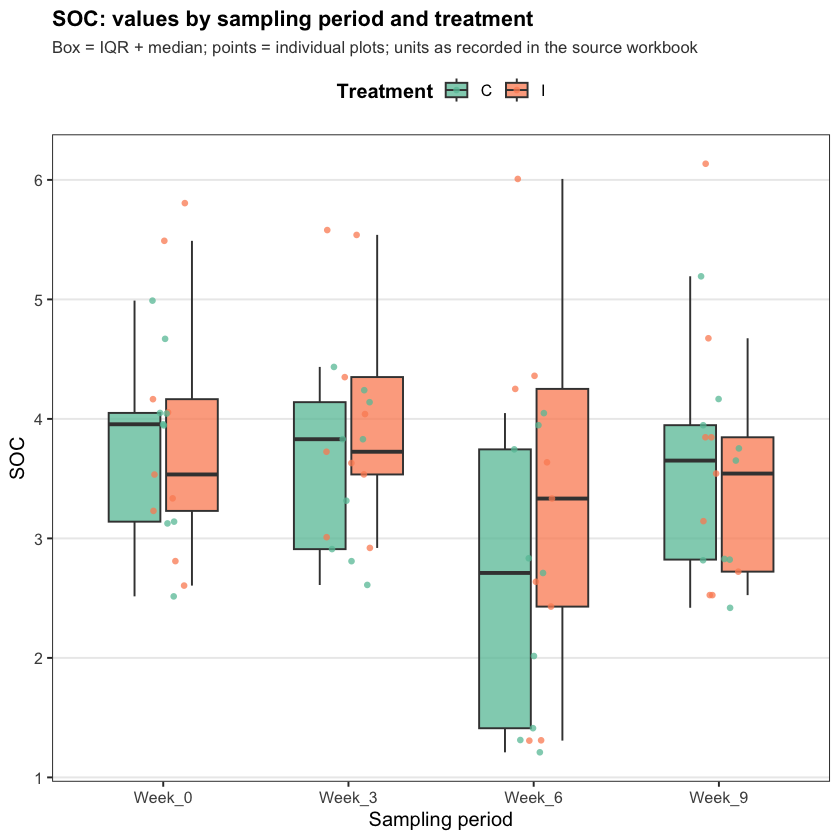

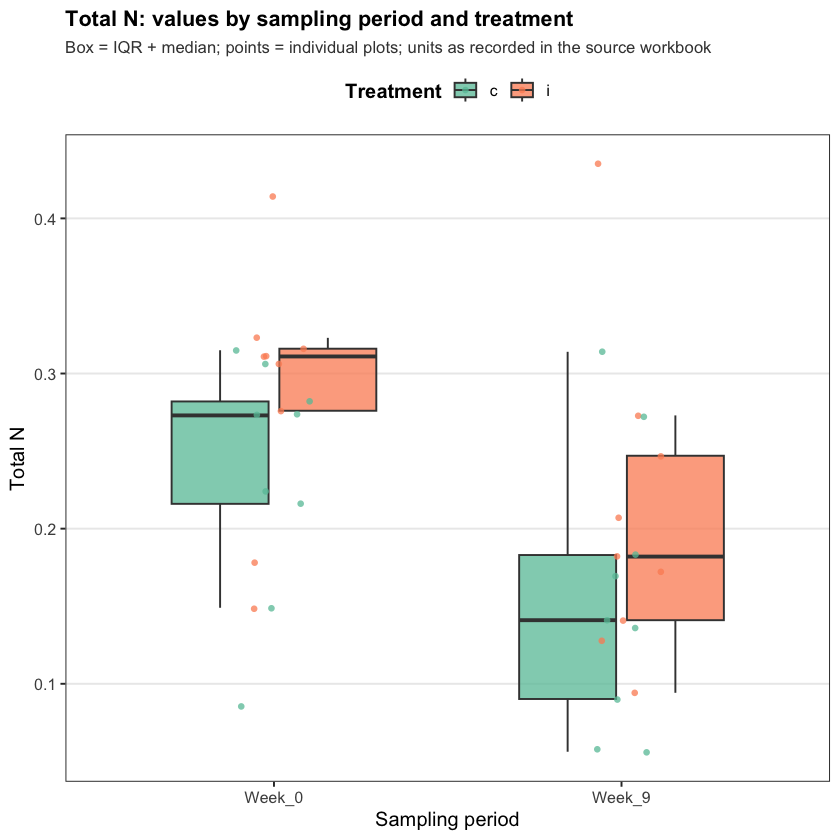


Saved: figures/fig_carbon_boxplot.png, figures/fig_nitrogen_boxplot.png, figures/fig_phosphorus_boxplot.png 


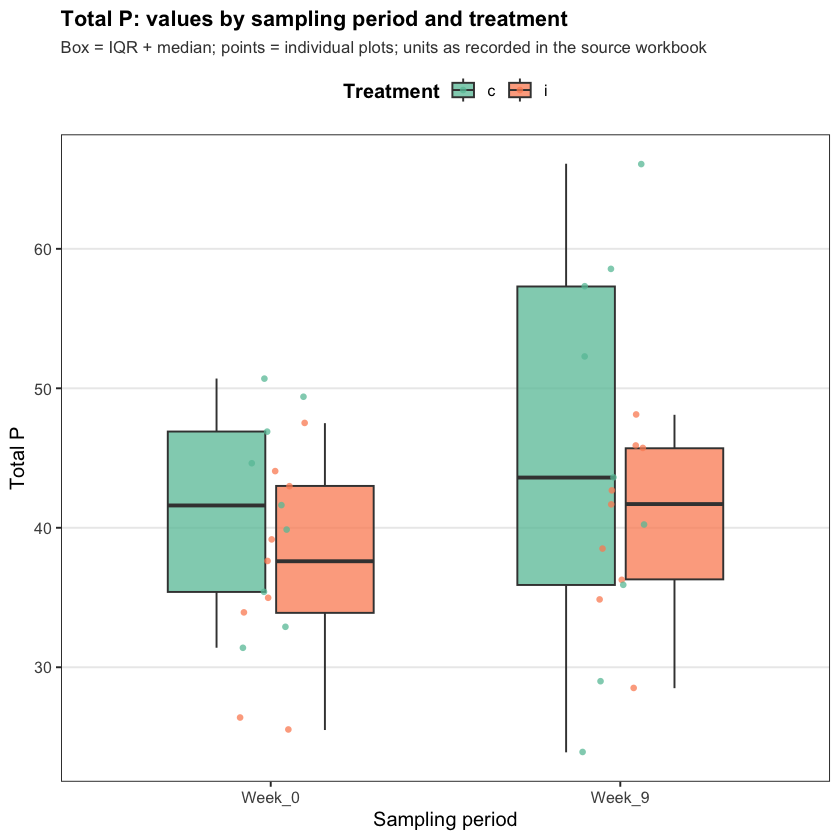

In [24]:
fig_box_files <- c()
for (nm in nut_order) {
  d <- soil %>% filter(nutrient == nm)
  p <- ggplot(d, aes(x = period, y = response, fill = treatment)) +
    geom_boxplot(outlier.shape = NA, alpha = 0.75, width = 0.62, color = "grey25") +
    geom_jitter(aes(colour = treatment), width = 0.12, size = 1.5, alpha = 0.75, shape = 16) +
    scale_fill_manual(values = scan_pal) +
    scale_colour_manual(values = scan_pal) +
    labs(
      title    = sprintf("%s: values by sampling period and treatment", nut_lab[[nm]]),
      subtitle = "Box = IQR + median; points = individual plots; units as recorded in the source workbook",
      x        = "Sampling period",
      y        = nut_lab[[nm]],
      fill     = "Treatment", colour = "Treatment"
    ) +
    theme_pub
  fn <- sprintf("figures/fig_%s_boxplot.png", tolower(nm))
  ggsave(fn, p, width = 7.2, height = 5, dpi = 300)
  fig_box_files <- c(fig_box_files, fn)
  print(p)
}
cat("\nSaved:", paste(fig_box_files, collapse = ", "), "\n")

## 2 - Model-based means: treatment x period interaction (response scale)

Back-transformed estimated marginal means from the Gamma GLMM (log link) with 95% CIs.


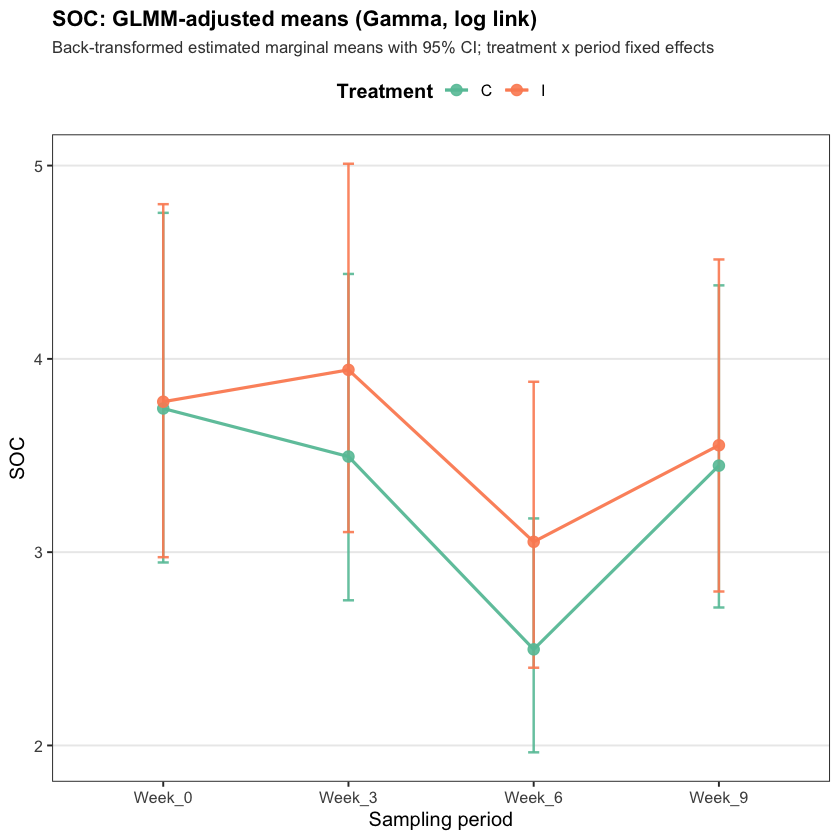

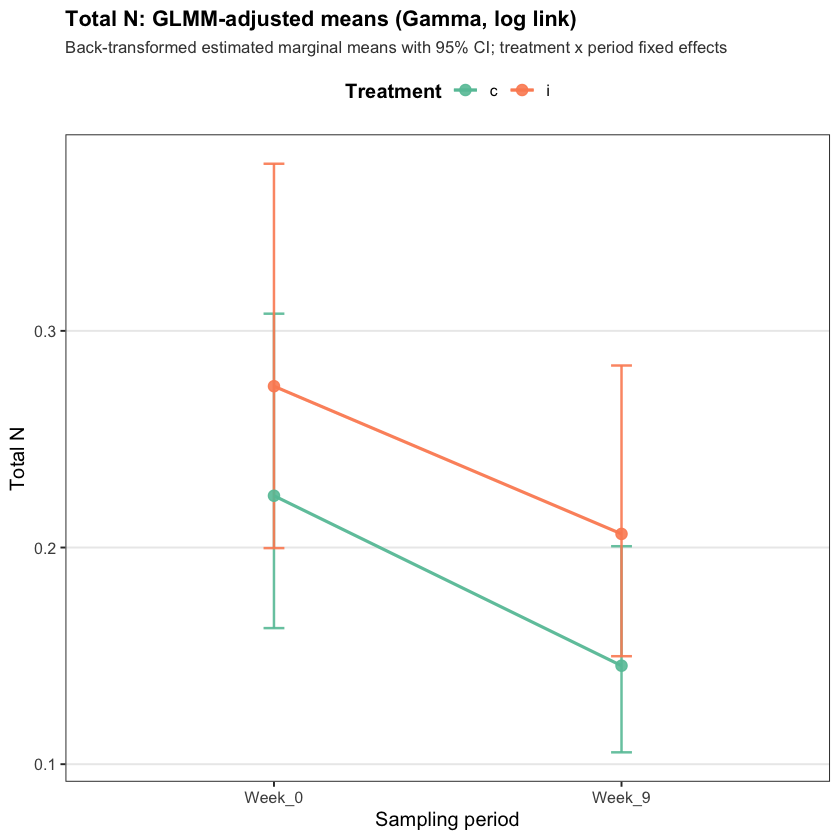


Saved: figures/fig_carbon_interaction_means.png, figures/fig_nitrogen_interaction_means.png, figures/fig_phosphorus_interaction_means.png 


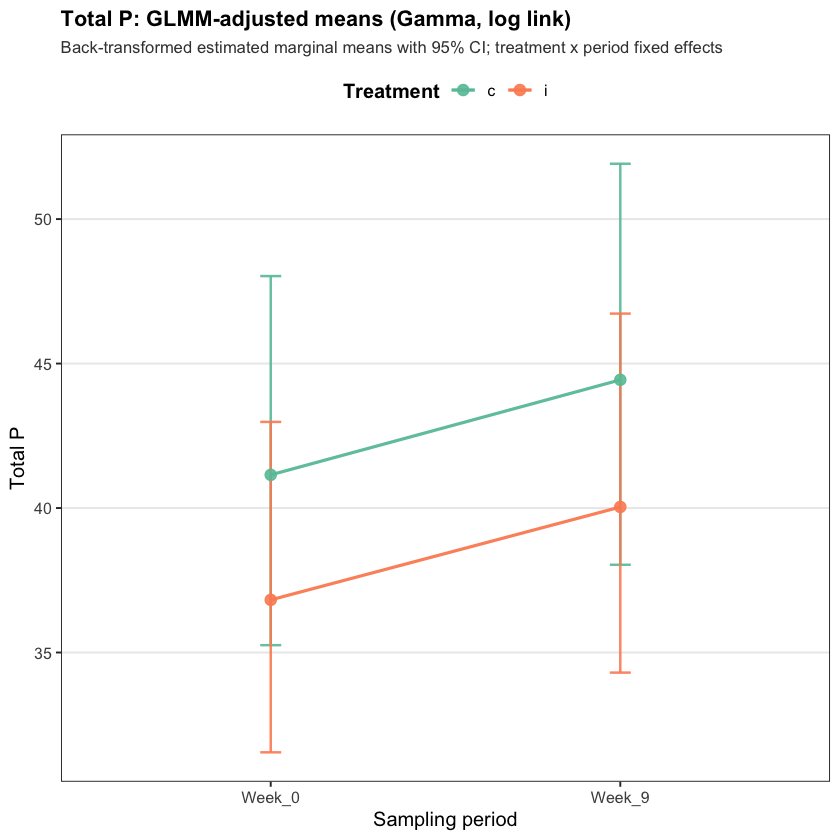

In [25]:
emm_fig_df <- bind_rows(lapply(nut_order, function(nm) {
  d <- as.data.frame(summary(pack$emm[[nm]], level = 0.95, infer = c(TRUE, TRUE)))
  names(d)[names(d) %in% c("response", "emmean", "rate")] <- "mean"
  names(d)[names(d) == "asymp.LCL"] <- "lower.CL"
  names(d)[names(d) == "asymp.UCL"] <- "upper.CL"
  d$nutrient <- nm
  d
}))

fig_int_files <- c()
for (nm in nut_order) {
  d <- emm_fig_df %>% filter(nutrient == nm)
  p <- ggplot(d, aes(x = period, y = mean, group = treatment, colour = treatment)) +
    geom_errorbar(aes(ymin = lower.CL, ymax = upper.CL), width = 0.06, linewidth = 0.7, alpha = 0.9) +
    geom_line(linewidth = 0.9, alpha = 0.95) +
    geom_point(size = 2.8, alpha = 0.9) +
    scale_colour_manual(values = scan_pal) +
    labs(
      title    = sprintf("%s: GLMM-adjusted means (Gamma, log link)", nut_lab[[nm]]),
      subtitle = "Back-transformed estimated marginal means with 95% CI; treatment x period fixed effects",
      x        = "Sampling period",
      y        = nut_lab[[nm]],
      colour   = "Treatment"
    ) +
    theme_pub
  fn <- sprintf("figures/fig_%s_interaction_means.png", tolower(nm))
  ggsave(fn, p, width = 7.2, height = 5, dpi = 300)
  fig_int_files <- c(fig_int_files, fn)
  print(p)
}
cat("\nSaved:", paste(fig_int_files, collapse = ", "), "\n")

## 3 - Treatment-ratio forest plot (control vs impact per period)

Ratio = control-type / impact-type from `pairs()` on the response scale. Ratio > 1: control-type higher; ratio < 1: impact-type higher.


Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


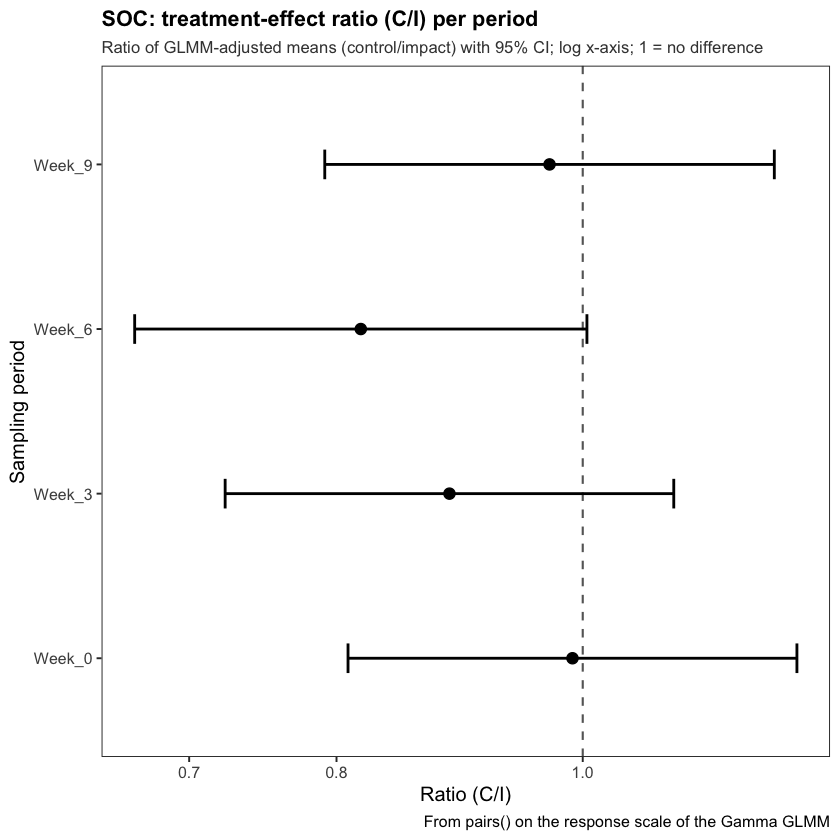

`height` was translated to `width`.


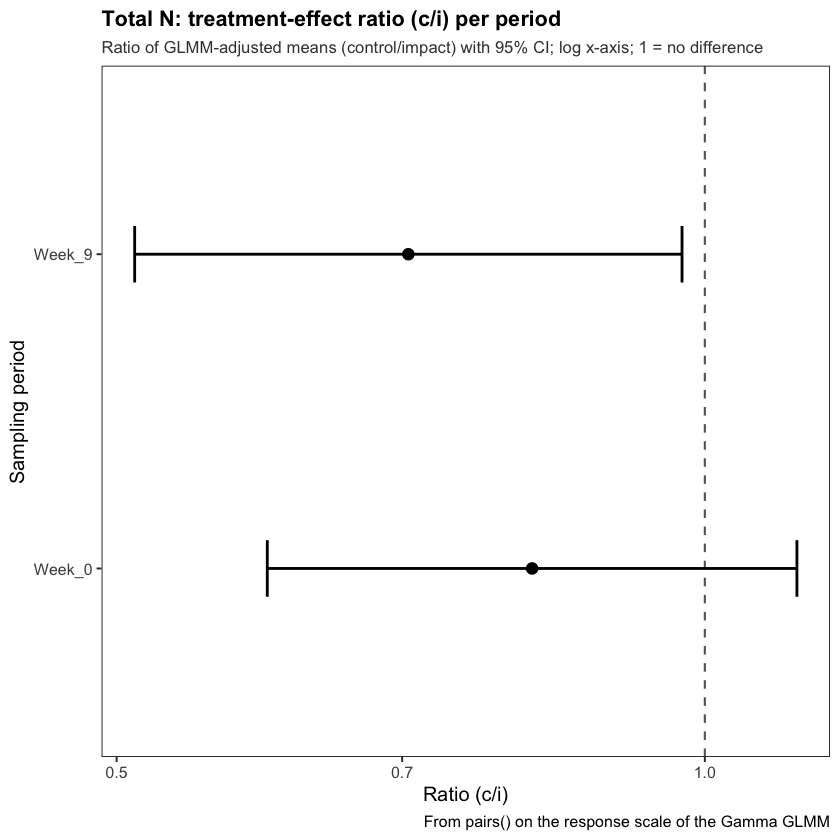


Saved: figures/fig_carbon_ratio_forest.png, figures/fig_nitrogen_ratio_forest.png, figures/fig_phosphorus_ratio_forest.png 


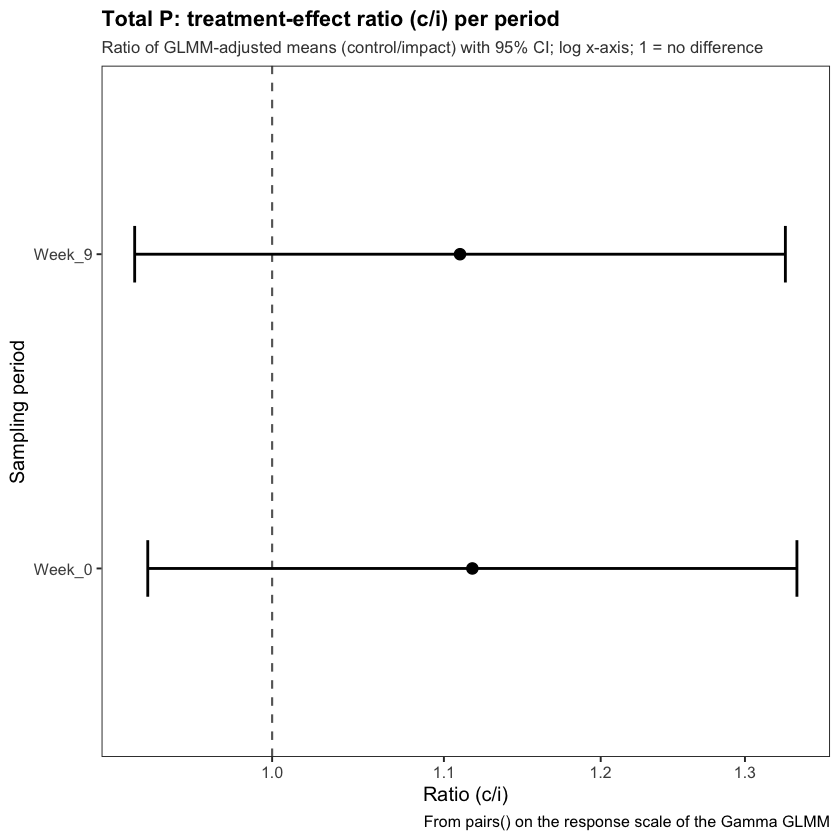

In [26]:
pair_fig_df <- bind_rows(lapply(nut_order, function(nm) {
  s <- as.data.frame(summary(pairs(pack$emm[[nm]]), infer = c(TRUE, TRUE), type = "response", adjust = "holm"))
  s$nutrient <- nm
  s
}))
estcol <- intersect(names(pair_fig_df), c("ratio", "effect", "odds.ratio"))[1]
if (is.na(estcol)) estcol <- names(pair_fig_df)[sapply(pair_fig_df, is.numeric)][1]
names(pair_fig_df)[names(pair_fig_df) == estcol] <- "ratio"
names(pair_fig_df)[names(pair_fig_df) %in% c("asymp.LCL", "lower.CL", "lower")] <- "LCL"
names(pair_fig_df)[names(pair_fig_df) %in% c("asymp.UCL", "upper.CL", "upper")] <- "UCL"
trt_ref <- c(Carbon = "C/I", Nitrogen = "c/i", Phosphorus = "c/i")

fig_ratio_files <- c()
for (nm in nut_order) {
  d <- pair_fig_df %>% filter(nutrient == nm)
  p <- ggplot(d, aes(x = ratio, y = period)) +
    geom_vline(xintercept = 1, linetype = "dashed", color = "grey40", linewidth = 0.6) +
    geom_errorbarh(aes(xmin = LCL, xmax = UCL), height = 0.18, linewidth = 0.8, color = "black") +
    geom_point(size = 2.8, color = "black") +
    scale_x_log10() +
    labs(
      title    = sprintf("%s: treatment-effect ratio (%s) per period", nut_lab[[nm]], trt_ref[[nm]]),
      subtitle = "Ratio of GLMM-adjusted means (control/impact) with 95% CI; log x-axis; 1 = no difference",
      x        = sprintf("Ratio (%s)", trt_ref[[nm]]),
      y        = "Sampling period",
      caption  = "From pairs() on the response scale of the Gamma GLMM"
    ) +
    theme_pub +
    theme(axis.text.y = element_text(angle = 0), panel.grid.major.y = element_blank())
  fn <- sprintf("figures/fig_%s_ratio_forest.png", tolower(nm))
  ggsave(fn, p, width = 7, height = 4.4, dpi = 300)
  fig_ratio_files <- c(fig_ratio_files, fn)
  print(p)
}
cat("\nSaved:", paste(fig_ratio_files, collapse = ", "), "\n")

## 4 - Combined overview (three nutrients, free y-scales)


Saved: figures/fig_overview.png


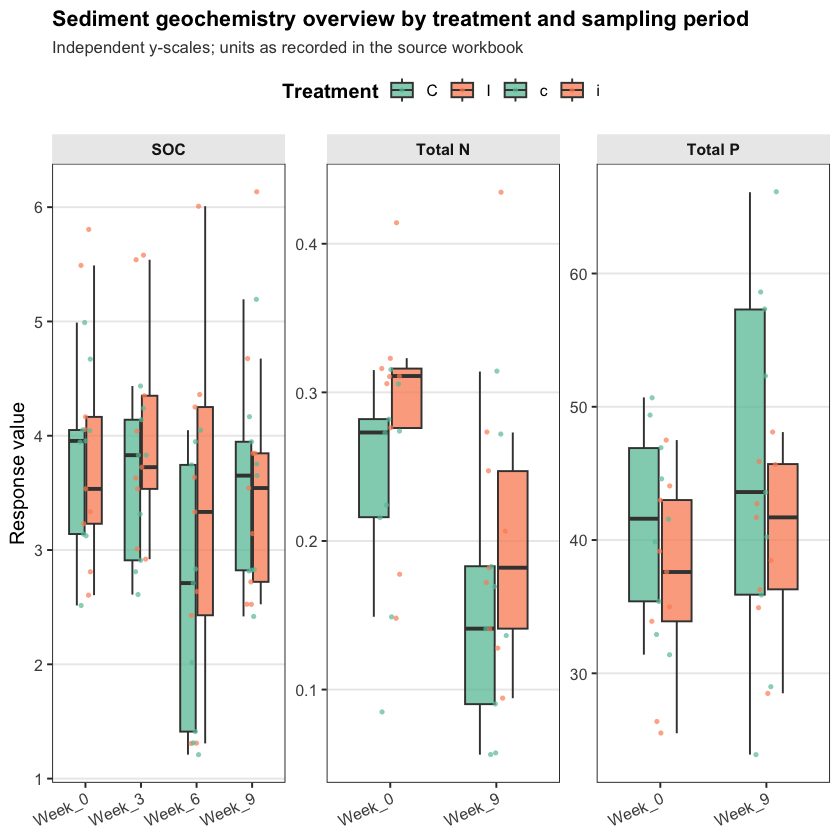

In [27]:
ov <- soil %>%
  filter(nutrient %in% nut_order) %>%
  group_by(nutrient) %>%
  mutate(period = droplevels(period)) %>%
  ungroup() %>%
  mutate(panel = nut_lab[nutrient])

p_ov <- ggplot(ov, aes(x = period, y = response, fill = treatment)) +
  geom_boxplot(outlier.shape = NA, alpha = 0.75, width = 0.62, color = "grey25") +
  geom_jitter(aes(colour = treatment), width = 0.1, size = 1.1, alpha = 0.7, shape = 16) +
  scale_fill_manual(values = scan_pal) +
  scale_colour_manual(values = scan_pal) +
  facet_wrap(~ panel, scales = "free", nrow = 1) +
  labs(
    title    = "Sediment geochemistry overview by treatment and sampling period",
    subtitle = "Independent y-scales; units as recorded in the source workbook",
    x        = NULL,
    y        = "Response value",
    fill     = "Treatment", colour = "Treatment"
  ) +
  theme_pub +
  theme(axis.text.x = element_text(angle = 25, hjust = 1))

ggsave("figures/fig_overview.png", p_ov, width = 11.5, height = 4.6, dpi = 300)
cat("Saved: figures/fig_overview.png\n")
print(p_ov)

## 5 - DHARMa residual diagnostics (all nutrients)

Left: residuals (log-predicted scale) vs scaled residuals (0-1; median = 0.5 line).
Right: QQ plot of scaled residuals against U(0,1) quantiles.


Saved: figures/fig_diagnostics.png



DHARMa test summary (from Notebook 02):


    panel   KS_p dispersion_p outliers_p
1     SOC 0.0645        0.958          1
2 Total N 0.2040        0.800          1
3 Total P 0.9160        0.508          1


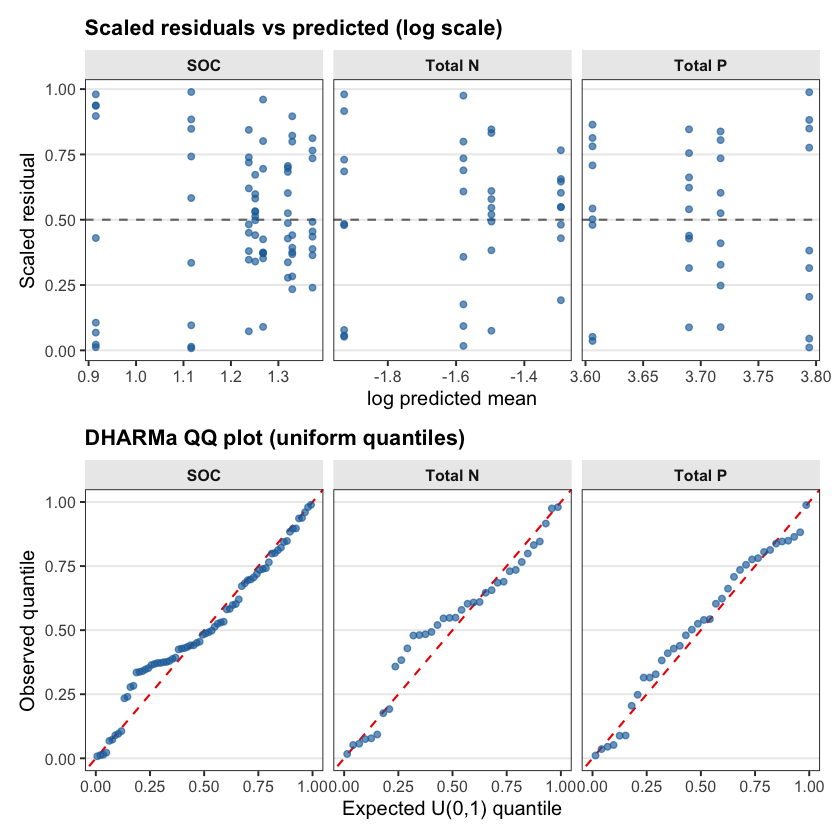

In [28]:
sim_meta <- bind_rows(lapply(nut_order, function(nm) {
  d <- pack$dh_tab %>% filter(nutrient == nm)
  d$panel <- nut_lab[[nm]]
  d
}))

diag_res <- bind_rows(lapply(nut_order, function(nm) {
  s  <- pack$sims[[nm]]
  fv <- s$fittedPredictedResponse
  if (is.null(fv) || length(fv) == 0) fv <- s$fittedResponse
  data.frame(nutrient = nm,
             panel    = nut_lab[[nm]],
             fitted   = log(as.numeric(fv)),
             resid    = as.numeric(s$scaledResiduals))
}))

diag_qq <- bind_rows(lapply(nut_order, function(nm) {
  s   <- pack$sims[[nm]]
  r   <- as.numeric(s$scaledResiduals)
  n   <- length(r)
  data.frame(nutrient = nm,
             panel    = nut_lab[[nm]],
             expected = ppoints(n),
             observed = sort(r))
}))

p_res <- ggplot(diag_res, aes(x = fitted, y = resid)) +
  geom_hline(yintercept = 0.5, linetype = "dashed", color = "grey45", linewidth = 0.6) +
  geom_point(size = 1.5, alpha = 0.65, color = "#1B6CA8") +
  facet_wrap(~ panel, scales = "free_x") +
  labs(title = "Scaled residuals vs predicted (log scale)", x = "log predicted mean", y = "Scaled residual") +
  theme_pub

p_qq <- ggplot(diag_qq, aes(x = expected, y = observed)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "red2", linewidth = 0.6) +
  geom_point(size = 1.5, alpha = 0.65, color = "#1B6CA8") +
  xlim(0, 1) + ylim(0, 1) +
  facet_wrap(~ panel) +
  labs(title = "DHARMa QQ plot (uniform quantiles)", x = "Expected U(0,1) quantile", y = "Observed quantile") +
  theme_pub

p_diag <- p_res / p_qq + plot_layout(guides = "collect") & theme_pub
ggsave("figures/fig_diagnostics.png", p_diag, width = 10, height = 8.4, dpi = 300)
cat("Saved: figures/fig_diagnostics.png\n")
print(p_diag)

cat("\nDHARMa test summary (from Notebook 02):\n")
print(as.data.frame(sim_meta %>% select(panel, KS_p, dispersion_p, outliers_p)))

## 6 - Figure inventory


In [29]:
figs <- list.files("figures", full.names = TRUE)
tab     <- data.frame(file = figs, size_kb = round(file.info(figs)$size / 1024, 1))
print(tab, row.names = FALSE)
cat("\nAll figures saved at 300 dpi PNG in figures/.\n")

                                         file size_kb
               figures/fig_carbon_boxplot.png    97.8
     figures/fig_carbon_interaction_means.png   121.1
          figures/fig_carbon_ratio_forest.png    88.1
                  figures/fig_diagnostics.png   377.5
             figures/fig_nitrogen_boxplot.png    80.5
   figures/fig_nitrogen_interaction_means.png   100.3
        figures/fig_nitrogen_ratio_forest.png    75.8
                     figures/fig_overview.png   170.8
           figures/fig_phosphorus_boxplot.png    81.2
 figures/fig_phosphorus_interaction_means.png    86.7
      figures/fig_phosphorus_ratio_forest.png    76.2



All figures saved at 300 dpi PNG in figures/.


In [30]:
cat("\n--- Session info (appendix) ---\n")
sessionInfo()


--- Session info (appendix) ---


R version 4.6.0 (2026-04-24)
Platform: aarch64-apple-darwin23
Running under: macOS Tahoe 26.6.2

Matrix products: default
BLAS:   /Library/Frameworks/R.framework/Versions/4.6/Resources/lib/libRblas.0.dylib 
LAPACK: /Library/Frameworks/R.framework/Versions/4.6/Resources/lib/libRlapack.dylib;  LAPACK version 3.12.1

locale:
[1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8

time zone: Asia/Manila
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] patchwork_1.3.2    scales_1.4.0       AICcmodavg_2.3-4   DHARMa_0.5.0       performance_0.19.0 emmeans_2.0.4      lme4_2.0-6         Matrix_1.7-5       car_3.1-5          carData_3.0-6      ggplot2_4.0.3     
[12] tidyr_1.3.2        dplyr_1.2.1        readxl_1.4.5      

loaded via a namespace (and not attached):
 [1] gtable_0.3.6       insight_1.6.0      lattice_0.22-9     vctrs_0.7.3        tools_4.6.0        Rdpack_2.6.6       generics_0.1.4    